**Visualisation of data using matplotlib and seaborn**

In [1]:
# You cannot visualize what you cannot understand
# importing core libraries
import numpy as np
import pandas as pd

#visualising libraries
import matplotlib.pyplot as plt
import seaborn as sns

# display settings
%matplotlib inline

In [2]:
# importing libraries suitable for downloading data online
import requests
import zipfile
import io

#specifying the url
url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"

# downloading the data set
response = requests.get(url)

#extracting the zip file
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
  z.extractall()
print("Dataset downloaded and extracted successfully")

Dataset downloaded and extracted successfully


In [3]:
# loading one (daily) data set
df = pd.read_csv("day.csv")
#displaying the first  rows
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
# exploring of data always begins with structural inspection
print("Dataset shape:",df.shape)

#looking for data types and missing values
df.info()

# basic summary statistics
df.describe()

Dataset shape: (731, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


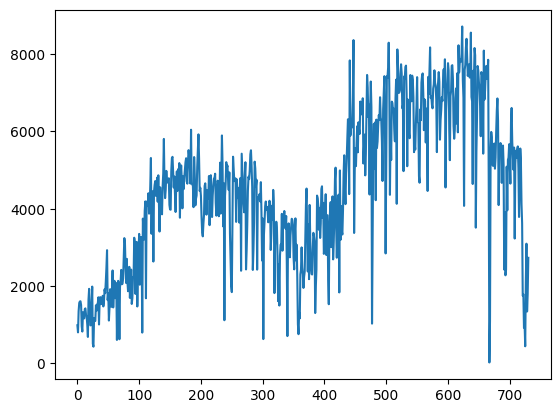

In [5]:
# first plot
plt.plot(df["cnt"])
plt.show()

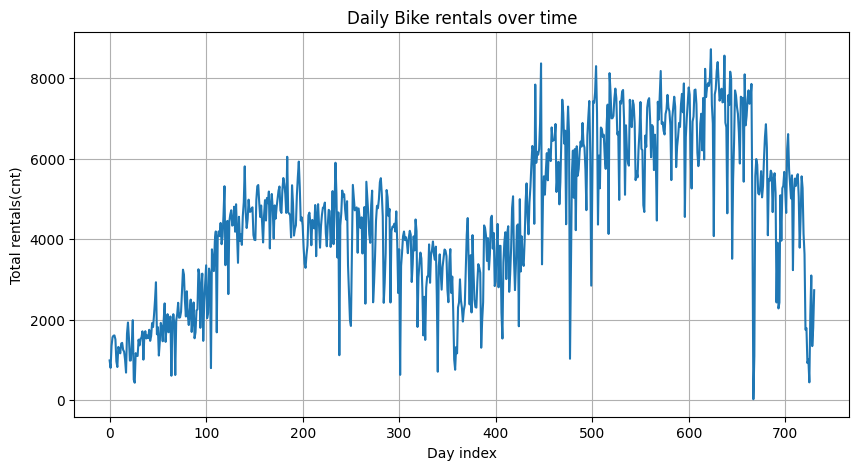

In [6]:
# qualiities of a good plot
plt.figure(figsize=(10,5))
plt.plot(df["cnt"])
plt.title("Daily Bike rentals over time")
plt.xlabel("Day index")
plt.ylabel("Total rentals(cnt)")
plt.grid(True)

plt.show()

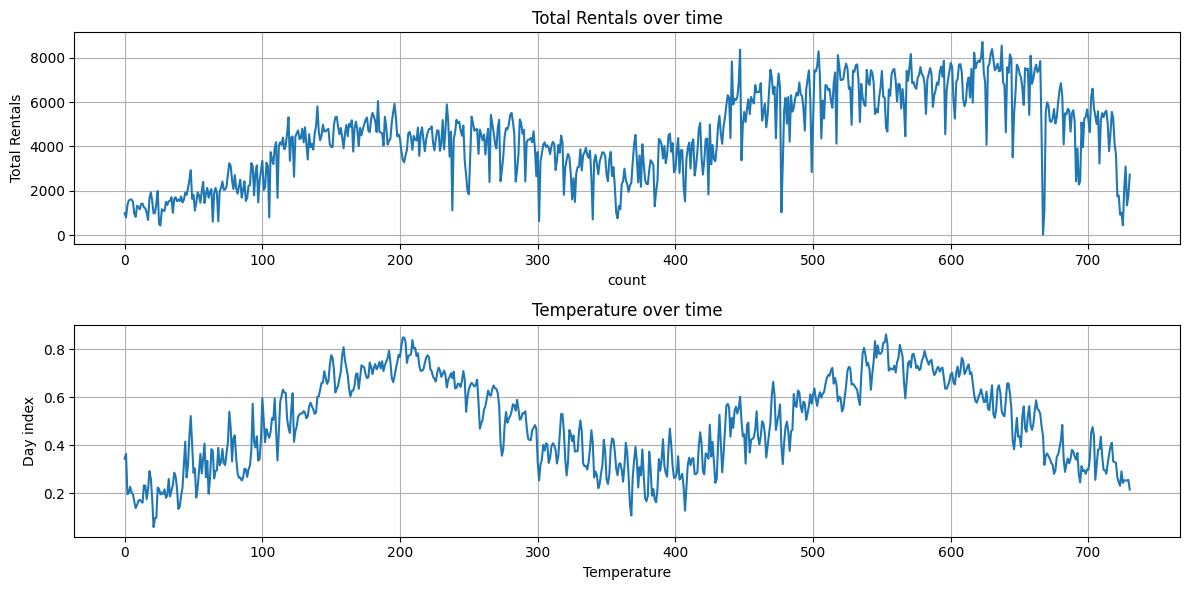

In [7]:
#Graph partioning
# specifying the size of the figure
plt.figure(figsize=(12,6))

#first subplot (2 rows,1 coloumn, postion 1)
plt.subplot(2,1,1)
plt.plot(df["cnt"])
plt.title("Total Rentals over time")
plt.xlabel("count")
plt.ylabel("Total Rentals")
plt.grid(True)

# second subplot (2,1,2)
plt.subplot(2,1,2)
plt.plot(df["temp"])
plt.title("Temperature over time")
plt.xlabel("Temperature")
plt.ylabel("Day index")
plt.grid(True)

plt.tight_layout()
plt.show()

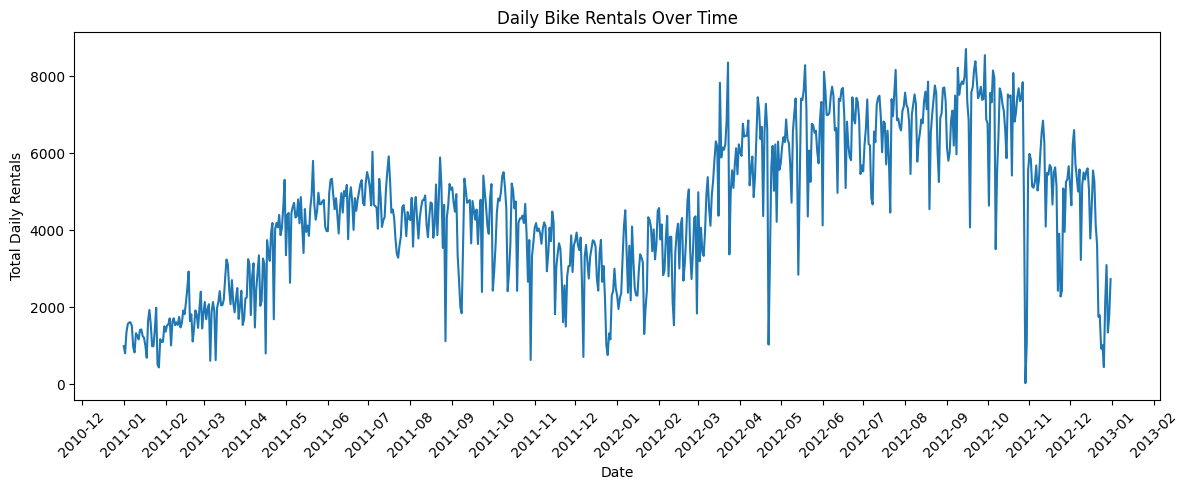

In [8]:
import matplotlib.dates as mdates

# Convert to datetime
df['dteday'] = pd.to_datetime(df['dteday'])

plt.figure(figsize=(12, 5))
plt.plot(df['dteday'], df['cnt'])

plt.title("Daily Bike Rentals Over Time")
plt.xlabel("Date")
plt.ylabel("Total Daily Rentals")

# Show one tick per month
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

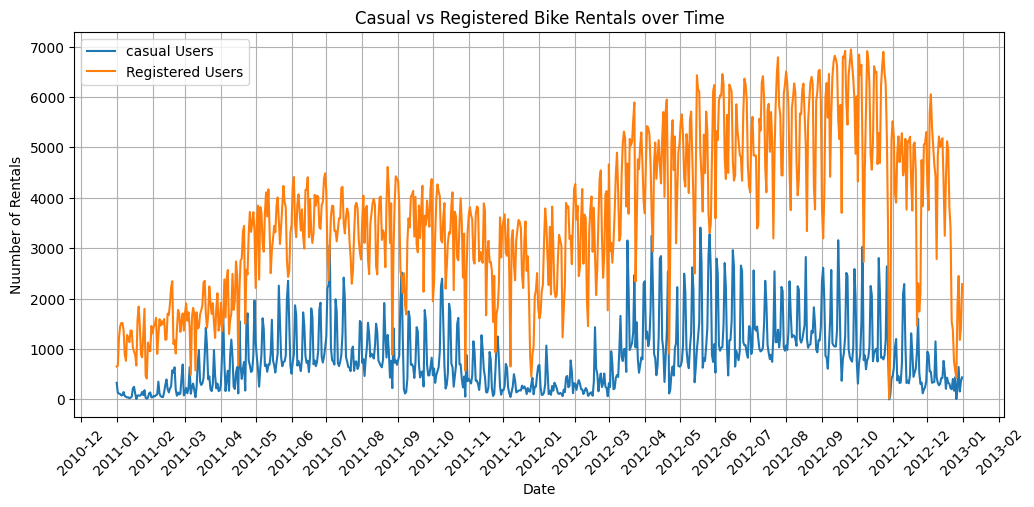

In [9]:
# Plotting multiple lines

plt.figure(figsize=(12,5))
plt.plot(df["dteday"],df["casual"], label="casual Users")
plt.plot(df["dteday"],df["registered"],label="Registered Users")

plt.title("Casual vs Registered Bike Rentals over Time")
plt.xlabel("Date")
plt.ylabel("Nuumber of Rentals")

#Monthly ticks
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.xticks(rotation=45)

plt.legend()
plt.grid(True)

plt.tight_layout
plt.show()

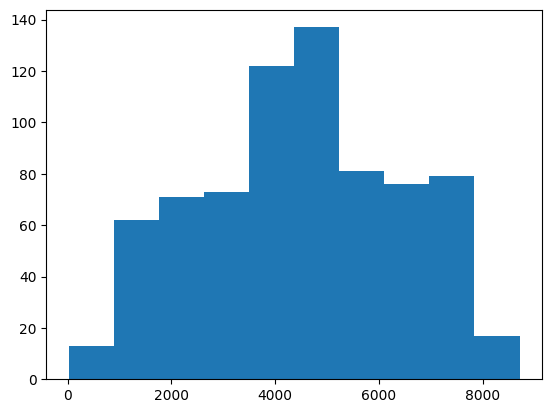

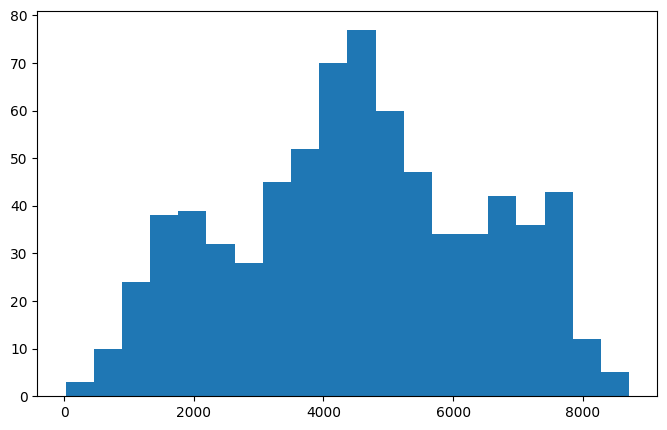

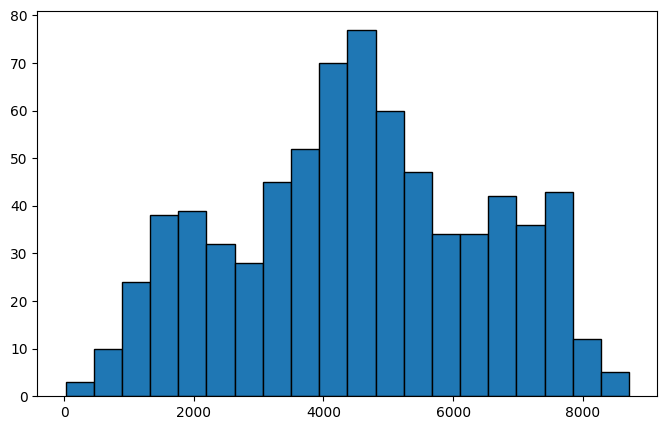

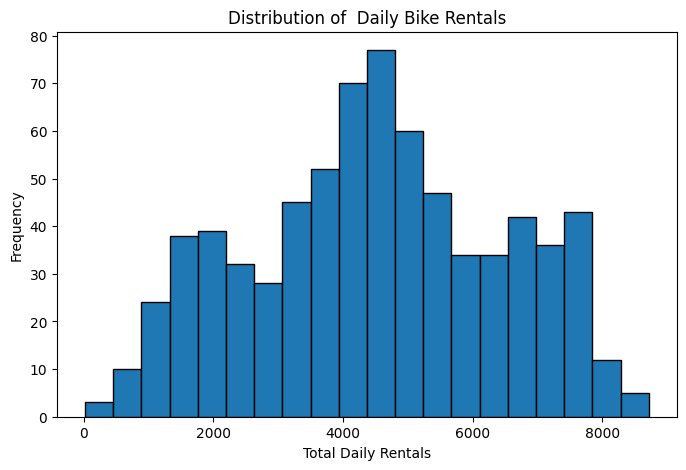

In [10]:
# Basic histogram
plt.hist(df['cnt'])
plt.show()
# increasing the bins
plt.figure(figsize=(8,5))
plt.hist(df['cnt'], bins =20) # 20 bins
plt.show()

#Adding edge
plt.figure(figsize=(8,5))
plt.hist(df['cnt'], bins = 20 , edgecolor= 'black')
plt.show()

#Add labels  and title
plt.figure(figsize=(8,5))
plt.hist(df['cnt'] , bins=20, edgecolor = 'black')
plt.title("Distribution of  Daily Bike Rentals")
plt.xlabel("Total Daily Rentals")
plt.ylabel("Frequency")
plt.show()

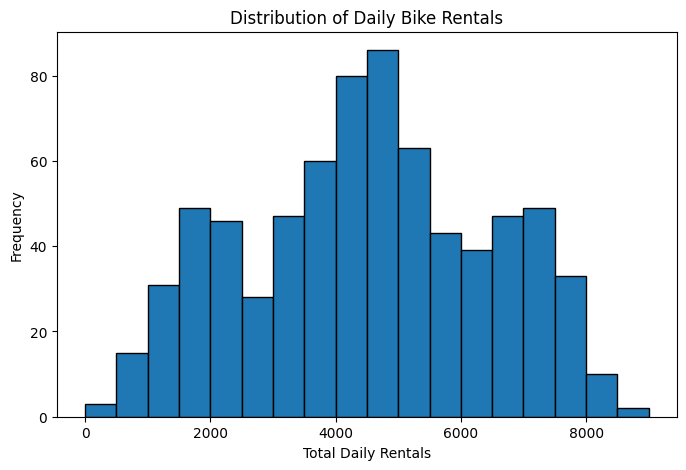

In [11]:
#Defining the bins effectively
bin_edges = np.arange(0,9500,500)
plt.figure(figsize=(8,5))
plt.hist(df['cnt'], bins=bin_edges, edgecolor='black')
plt.title("Distribution of Daily Bike Rentals")
plt.xlabel("Total Daily Rentals")
plt.ylabel("Frequency")
plt.show()

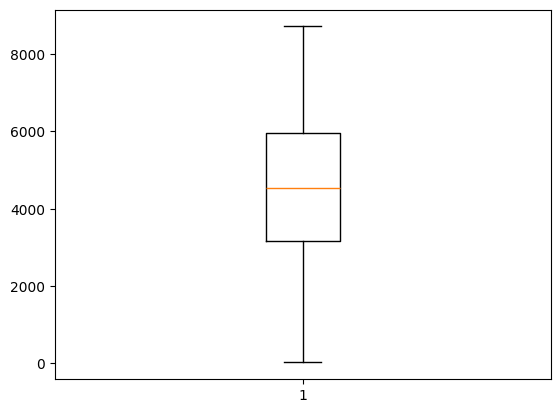

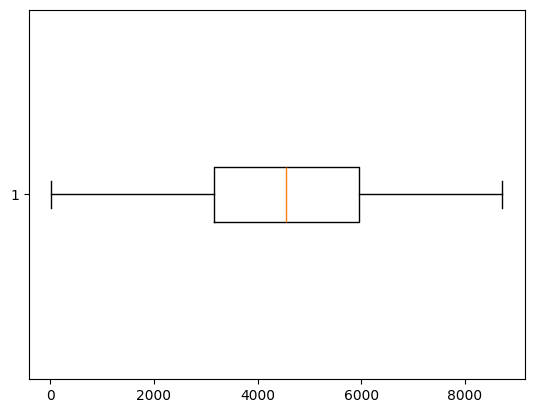

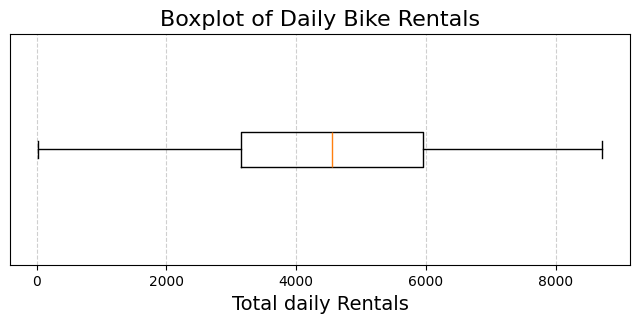

In [12]:
# Basic boxplot
plt.boxplot(df['cnt'])
plt.show()

# horizontal boxplot for readability
plt.boxplot(df['cnt'],vert =False)
plt.show()

#adding labels and tites
plt.figure(figsize=(8,3))

plt.boxplot(df['cnt'], vert=False)

plt.title("Boxplot of Daily Bike Rentals",fontsize=16)
plt.xlabel("Total daily Rentals", fontsize=14)

plt.yticks([]) # removing unnecessary categorical axis
plt.grid(axis="x", linestyle = "--", alpha = 0.6)

plt.show()

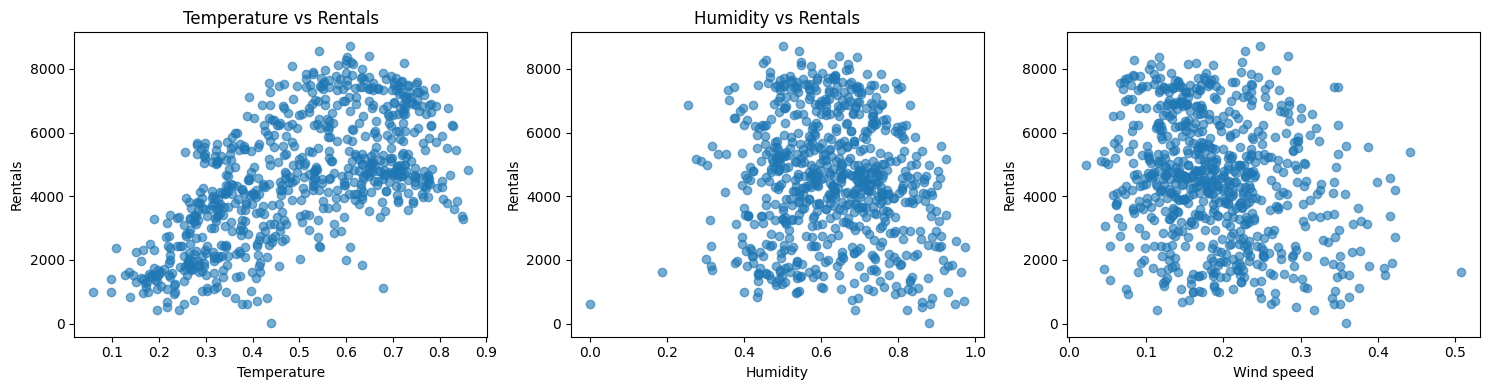

In [14]:
plt.figure(figsize=(15,4))
# Temperature vs Rentals
plt.subplot(1,3,1)
plt.scatter(df["temp"],df["cnt"], alpha=0.6)
plt.title("Temperature vs Rentals")
plt.xlabel("Temperature")
plt.ylabel("Rentals")

#Humidity vs Rentals
plt.subplot(1,3,2)
plt.scatter(df["hum"], df["cnt"],alpha=0.6)
plt.title("Humidity vs Rentals")
plt.xlabel("Humidity")
plt.ylabel("Rentals")

#Wind speed vs Rentals
plt.subplot(1,3,3)
plt.scatter(df["windspeed"],df["cnt"],alpha =0.6)
plt.xlabel("Wind speed")
plt.ylabel("Rentals")

plt.tight_layout()
plt.show()

In [15]:
# selecting the relevant numerical variables
numeric_df = df[["temp","hum","windspeed","casual","registered","cnt"]]

#computing correlation matrix
corr_matrix = numeric_df.corr()
corr_matrix

,temp,hum,windspeed,casual,registered,cnt
temp,1.000000,0.126963,-0.157944,0.543285,0.540012,0.627494
hum,0.126963,1.000000,-0.248489,-0.077008,-0.091089,-0.100659
windspeed,-0.157944,-0.248489,1.000000,-0.167613,-0.217449,-0.234545
casual,0.543285,-0.077008,-0.167613,1.000000,0.395282,0.672804
registered,0.540012,-0.091089,-0.217449,0.395282,1.000000,0.945517
cnt,0.627494,-0.100659,-0.234545,0.672804,0.945517,1.000000


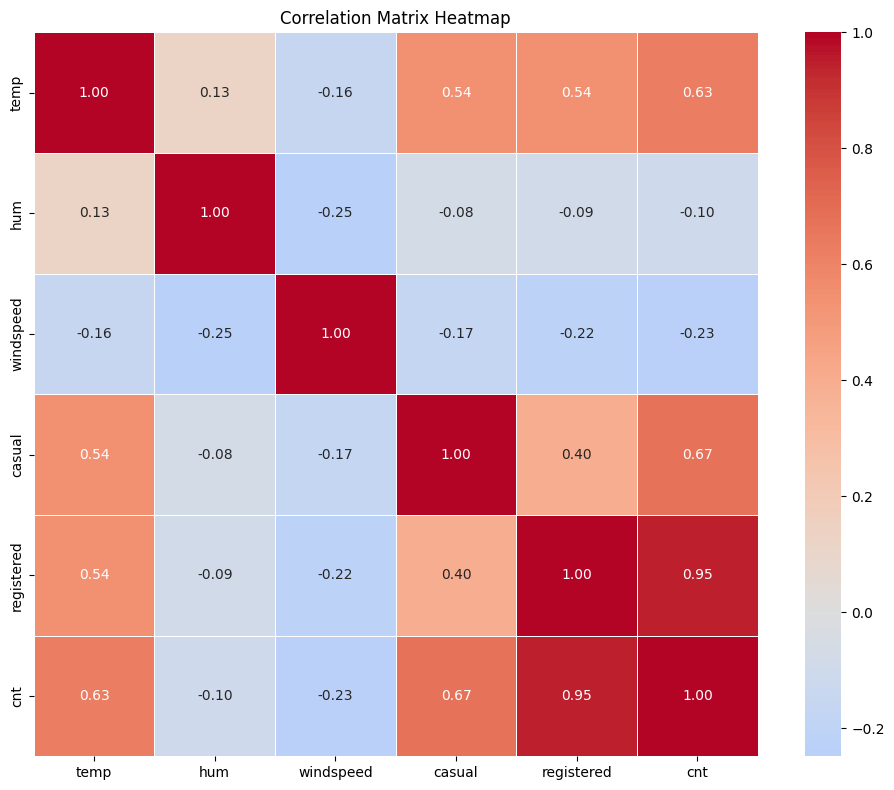

In [16]:
# visualising the correlation using a Heatmap
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm",fmt=".2f",center =0,square=True,linewidths=0.5)
plt.title("Correlation Matrix Heatmap")
plt.tight_layout()
plt.show()

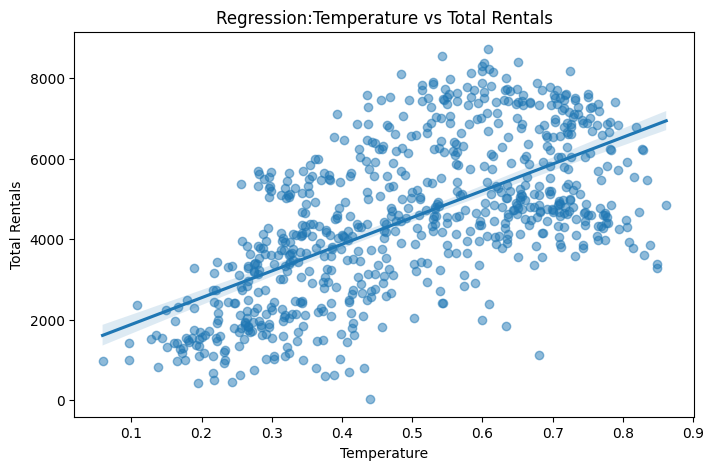

In [18]:
#Adding a regression line
#How temperature influence rental demand

plt.figure(figsize=(8,5))
sns.regplot(
    data=df,
    x="temp",
    y="cnt",
    scatter_kws={"alpha":0.5}
)
plt.title("Regression:Temperature vs Total Rentals")
plt.xlabel("Temperature")
plt.ylabel("Total Rentals")

plt.tight_layout
plt.show()

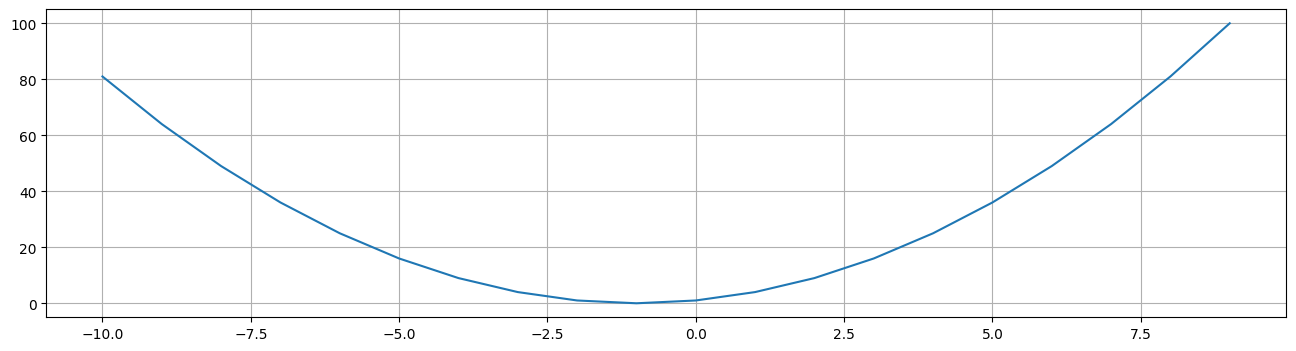

In [22]:
# using matplotlib you can easily plot any function
#Function definition
def my_function(x):
  return x ** 2 + 2 *x + 1
x = np.arange(-10, 10)
plt.figure(figsize = (16,4))
plt.plot(x, my_function(x))
plt.grid(True)

(array([ 0.,  2.,  4.,  6.,  8., 10., 12.]),
 [Text(0, 0.0, '0'),
  Text(0, 2.0, '2'),
  Text(0, 4.0, '4'),
  Text(0, 6.0, '6'),
  Text(0, 8.0, '8'),
  Text(0, 10.0, '10'),
  Text(0, 12.0, '12')])

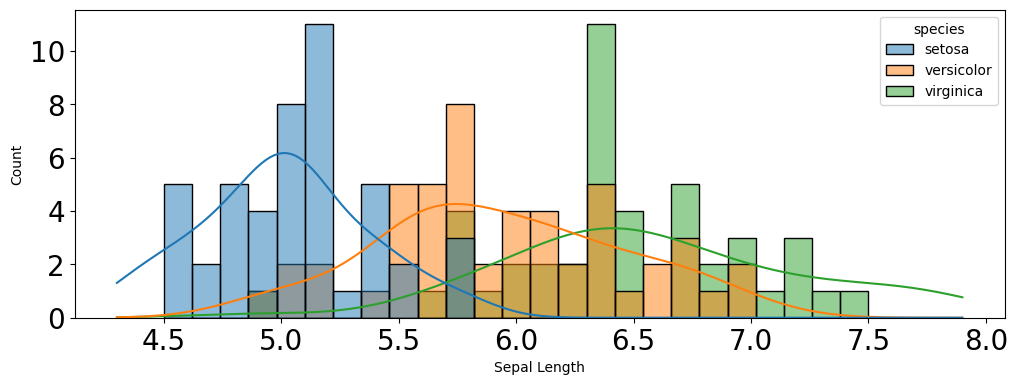

In [24]:
#KDE kernel density estimate
# Loading the iris dataset
iris = sns.load_dataset('iris')

plt.figure(figsize =(12,4))
sns.histplot(data=iris, x='sepal_length', hue='species', bins=25, binrange=(4.5,7.5), kde=True)
plt.xlabel('Sepal Length')
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)